# FIREGUARD ID v2 — Minggu 6: [P] Evaluation, Error Analysis, Lifecycle Feedback & Vulnerability
**Sesuai Ketentuan Minggu 6 (Bab 7–9 L-M-O-P, Adaptasi Unsupervised Clustering):**
- **Bab 7.1 (Metrik & Justifikasi):** Silhouette Score, Davies-Bouldin Index (DBI), Calinski-Harabasz Index (CHI), Multi-Seed/Subsample ARI, Spatial-Block Fold ARI, dan Spatial Coherence Lift — **tanpa** Accuracy/Precision/Recall/F1.
- **Bab 7.2 (Evaluasi pada Holdout Spasial):** Evaluasi *Leave-One-Quadrant-Out* (`NE/NW/SE/SW`) dengan scaler & model fit hanya pada 3 kuadran training.
- **Bab 7.3 (Perbandingan 3 Model + Compute Timing):** K-Means (`k=3`), HDBSCAN (`k=8`, noise `22.39%`), dan DEC (`k=3`) termasuk `training_time_seconds` dan `inference_time_seconds`.
- **Bab 7.4 (Error Analysis, Generalization Gap & Inductive Bias):** Analisis ketidaksepakatan `108` sel K-Means vs DEC, anatomi `191` sel noise `-1` HDBSCAN (`79.06%` hotspot), dan celah generalisasi antar kuadran.
- **Bab 7.5 & Bab 8 (Umpan Balik Lifecycle L→M→O & Goals):** Tabel iterasi perbaikan + post-hoc vulnerability mapping (`87.34%` K-Means/DEC concordance).

In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src.utils import load_yaml, resolve_path
proj_cfg = load_yaml('config/project.yaml', repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Perbandingan Ketiga Model & Waktu Komputasi (Bab 7.1 & 7.3)

,model,selected_config,n_clusters,noise_ratio,metric_scope,silhouette_feature,davies_bouldin_feature,calinski_harabasz_feature,multi_seed_mean_ari,spatial_fold_mean_ari,neighbor_concordance,coherence_lift,min_cluster_share,max_cluster_share,training_time_seconds,inference_time_seconds
0,K-Means (Baseline),"k=3, n_init=30",3,0.000000,All 853 cells (Euclidean feature space),0.544178,0.714354,1261.7150,1.000000,0.972507,0.554477,1.2880,0.091442,0.522860,0.3147,0.002540
1,HDBSCAN (Density-Based),"min_cluster_size=15, min_samples=10, method=eom",8,0.223916,Non-noise subset (662/853 cells; 191 noise=-1),0.643293,0.882913,1656.8601,0.971355,0.949771,0.305707,1.4778,0.045317,0.376133,0.0121,0.001020
2,DEC (Deep Embedded Clustering),"n_clusters=3, latent_dim=4, gamma_recon=0.1",3,0.000000,All 853 cells (Feature-space eval; Latent Sil=...,0.480230,0.847784,969.6476,0.685752,0.880687,0.514402,1.3212,0.198124,0.520516,11.0475,0.004217


Cross-model agreement: {
  "kmeans_vs_dec_ari": 0.770002,
  "kmeans_vs_dec_nmi": 0.71046,
  "kmeans_vs_hdbscan_non_noise_ari": 0.351406,
  "dec_vs_hdbscan_non_noise_ari": 0.351889
}
Primary Recommendation: K-Means (k=3)


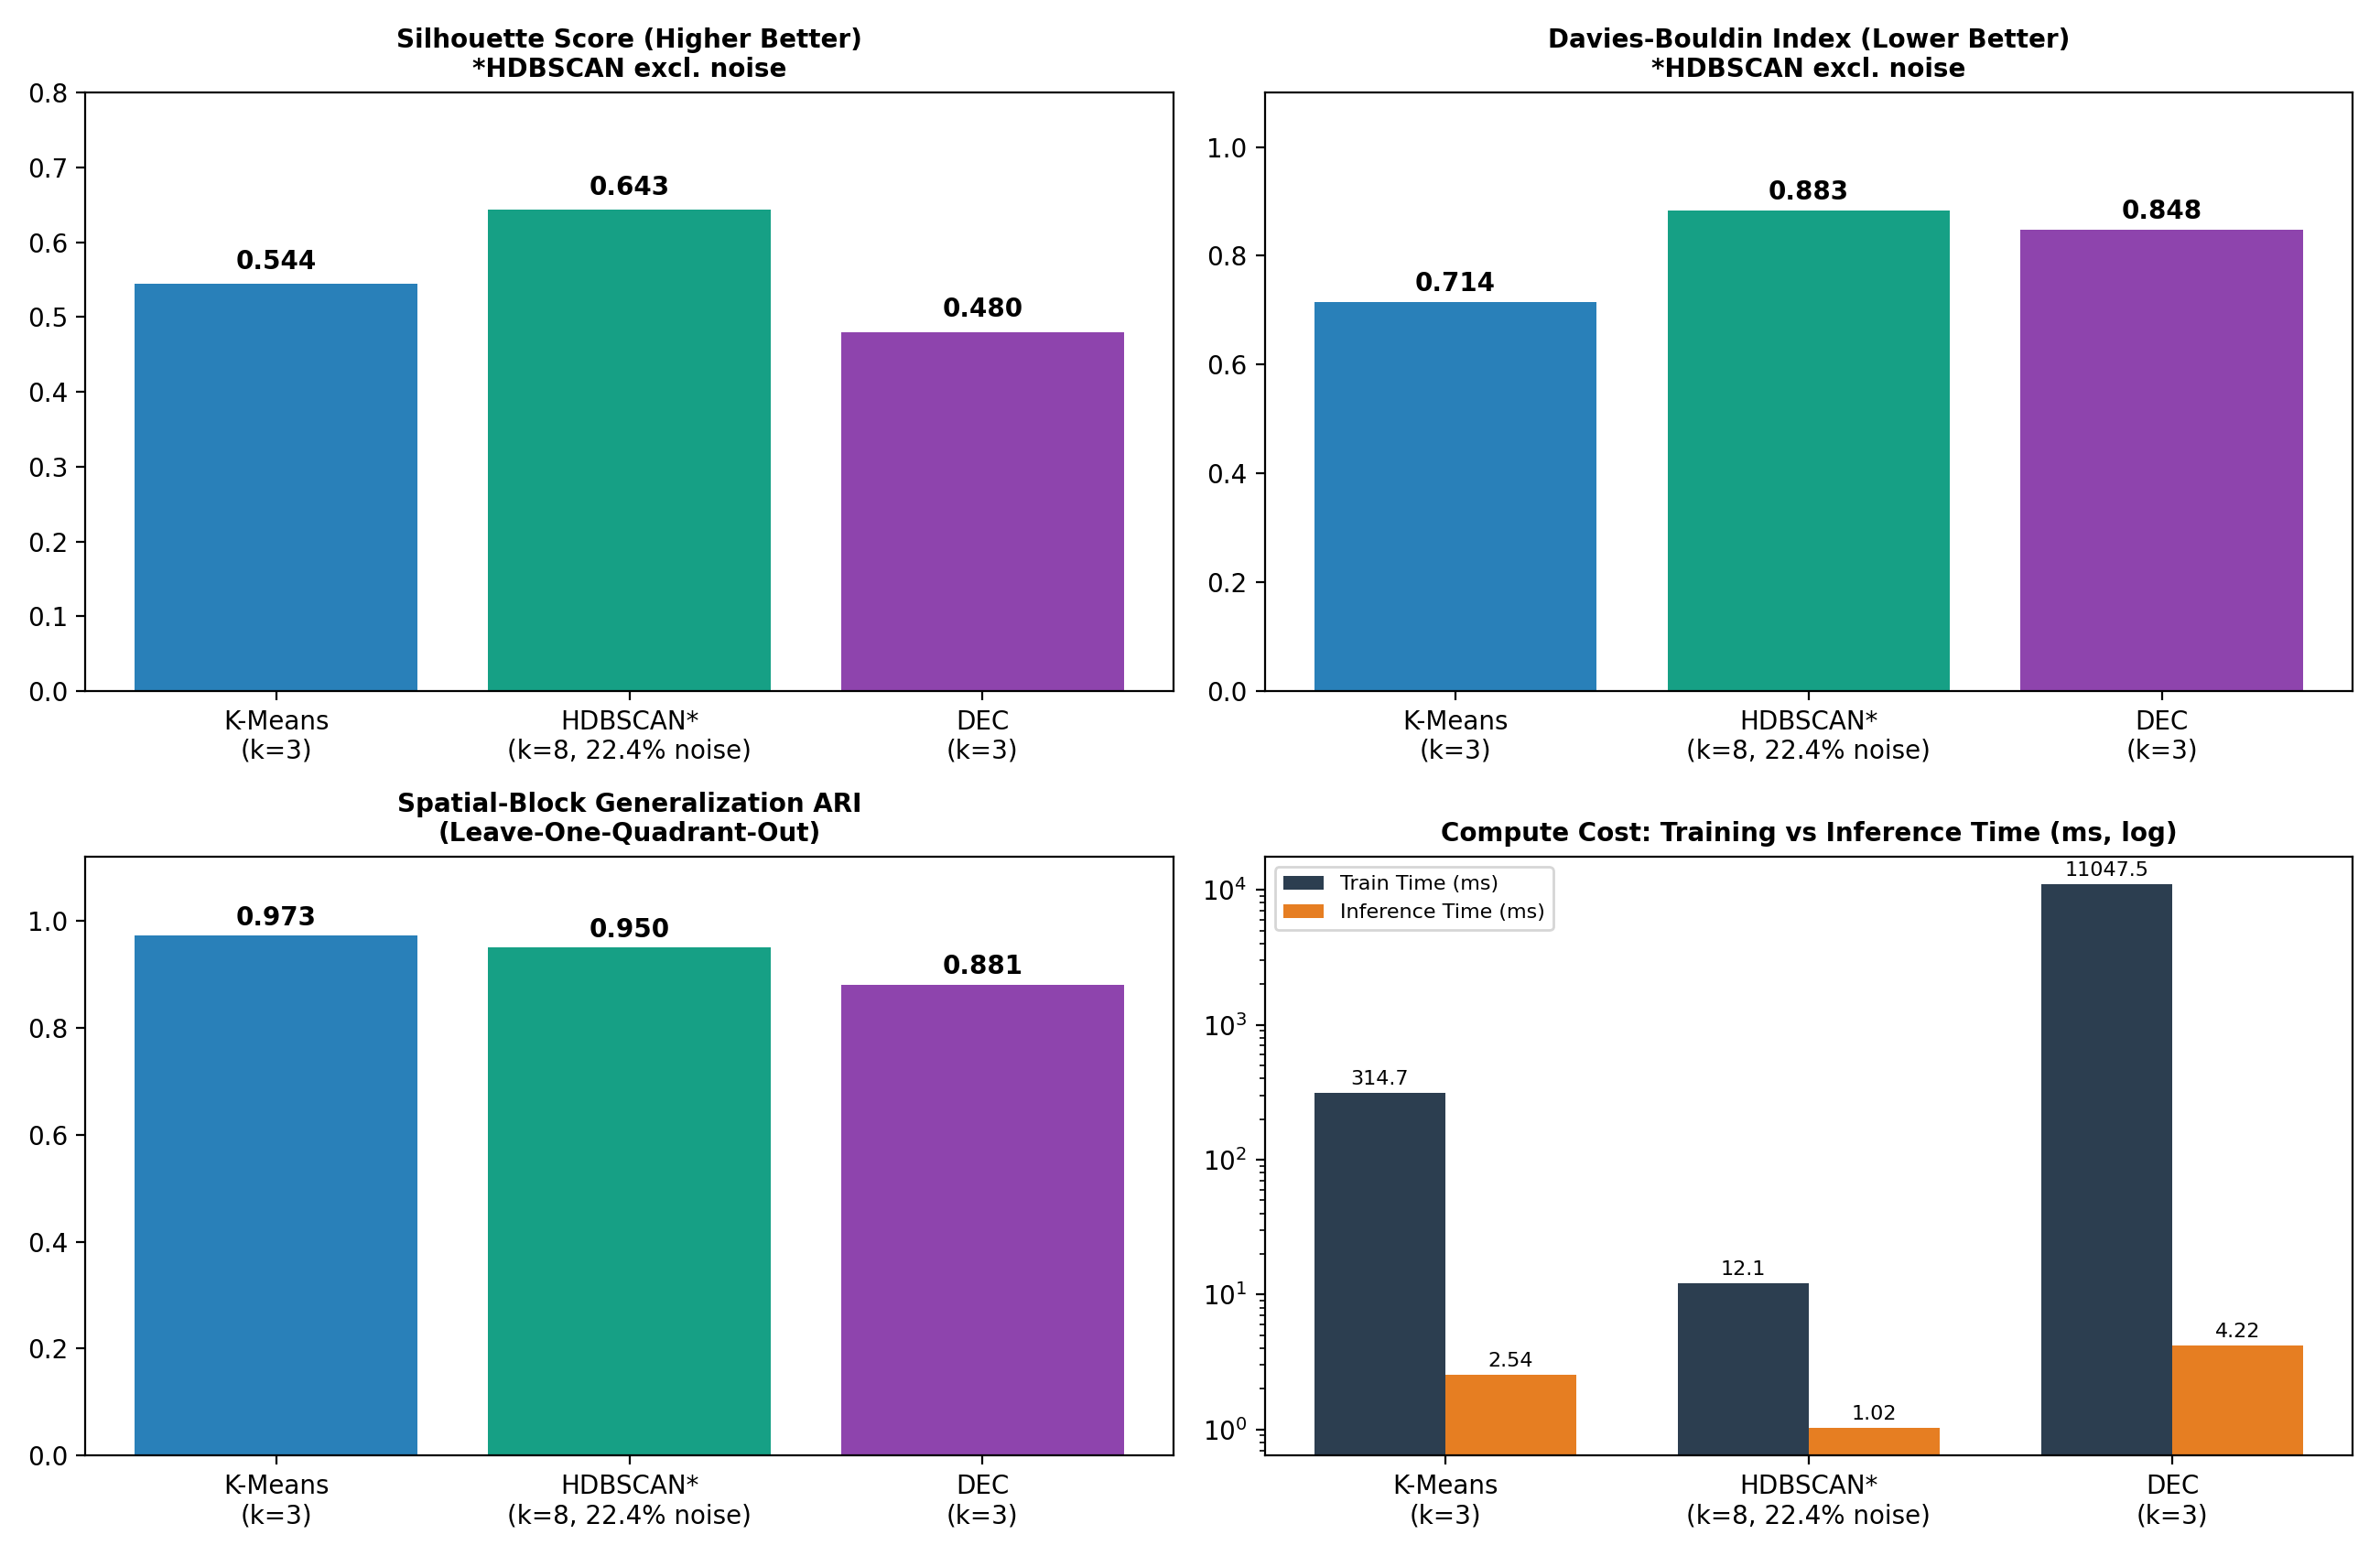

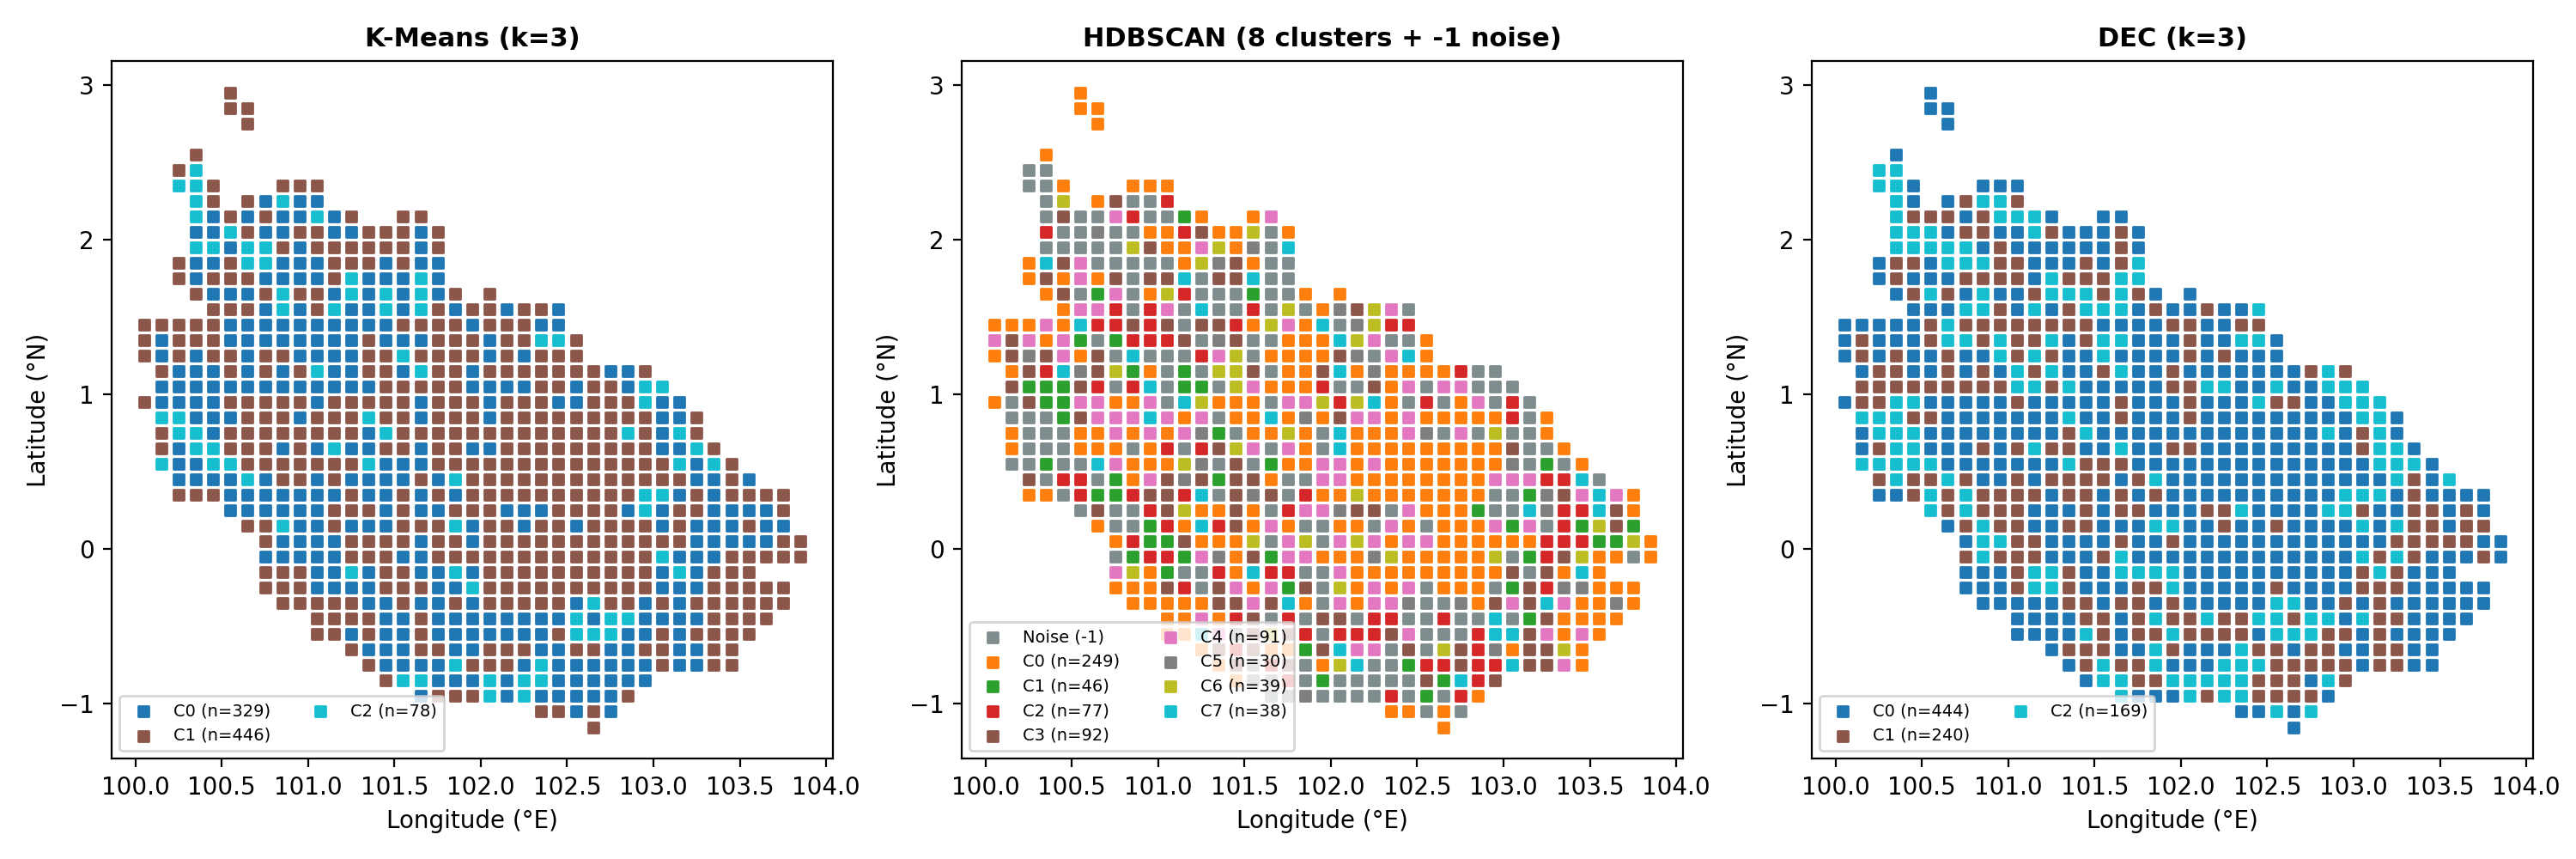

In [2]:
reports_dir = resolve_path(proj_cfg['paths']['reports_dir'], repo_root=REPO_ROOT)
comp_df = pd.read_csv(reports_dir / 'clustering' / 'model_comparison.csv')
v2_reg = json.loads((reports_dir / 'clustering' / 'model_comparison_v2.json').read_text(encoding='utf-8'))
display(comp_df)
print('Cross-model agreement:', json.dumps(v2_reg['cross_model_agreement'], indent=2))
print('Primary Recommendation:', v2_reg['recommendation']['primary_operational_baseline'])
display(Image(filename=str(reports_dir / 'clustering' / 'model_comparison_plots.png')))
display(Image(filename=str(reports_dir / 'clustering' / 'spatial_clusters_comparison.png')))

## 2. Evaluasi Holdout Spasial & Stabilitas Multi-Seed (Bab 7.2)

In [3]:
display(Markdown((reports_dir / 'clustering' / 'spatial_validation_report.md').read_text(encoding='utf-8')))
display(Markdown((reports_dir / 'clustering' / 'stability_report.md').read_text(encoding='utf-8')))
ext_exp = v2_reg.get('extended_feature_experiment', {})
print('Extended 8-feature ablation decision:', ext_exp.get('schema_decision'))

# FIREGUARD ID v2 — Spatial-Block Generalization & Coherence Report

## 1. Leave-One-Quadrant-Out Spatial Block Protocol
- Riau's 853 cells are partitioned around median centroid coordinates into 4 geographic quadrants (`NE=150, NW=281, SE=293, SW=129`).
- Scalers and models are fit strictly on the 3 training quadrants and evaluated on the held-out quadrant to prevent spatial leakage.

## 2. Per-Fold Results (K-Means k=3 & DEC k=3)
| held_out_quadrant   |   n_test_cells |   kmeans_test_sil |   kmeans_transfer_ari |   dec_test_sil_feat |   dec_transfer_ari |
|:--------------------|---------------:|------------------:|----------------------:|--------------------:|-------------------:|
| NE                  |            150 |          0.558979 |              0.967125 |            0.500045 |           0.919199 |
| NW                  |            281 |          0.504832 |              0.929049 |            0.442728 |           0.885445 |
| SE                  |            293 |          0.566743 |              0.993853 |            0.511153 |           0.945771 |
| SW                  |            129 |          0.518303 |              1        |            0.532989 |           0.772335 |

## 3. HDBSCAN Spatial-Fold Stability & Queen-Neighbor Coherence
- HDBSCAN 4-Fold Mean ARI vs Full: **0.949771** (min: `0.912508`)
- Spatial Coherence Lift (Queen Adjacency): K-Means=`1.288x`, HDBSCAN=`1.4778x`, DEC=`1.3212x`


# FIREGUARD ID v2 — Multi-Seed & Subsample Stability Report

## 1. K-Means Multi-Seed Stability (Seeds: 42, 101, 202, 303, 404)
|   k |   silhouette |      dbi |   seed_mean_ari |   seed_min_ari |   min_share |
|----:|-------------:|---------:|----------------:|---------------:|------------:|
|   2 |     0.543706 | 0.807048 |        1        |       1        |    0.315358 |
|   3 |     0.544178 | 0.714354 |        1        |       1        |    0.091442 |
|   4 |     0.524246 | 0.805993 |        0.982952 |       0.960205 |    0.057444 |
|   5 |     0.5165   | 0.819181 |        0.995779 |       0.991178 |    0.037515 |
|   6 |     0.534711 | 0.825204 |        0.99905  |       0.997626 |    0.038687 |
|   7 |     0.550538 | 0.77969  |        0.986055 |       0.977272 |    0.036342 |
|   8 |     0.551179 | 0.770737 |        0.986463 |       0.977881 |    0.003517 |

## 2. HDBSCAN 80% Subsample Stability (Selected `min_cluster_size=15, min_samples=10, eom`)
- Mean ARI vs Full: **0.971355** (min: `0.965665`)
- Pairwise Overlap Mean ARI: **0.971171**

## 3. DEC Multi-Seed Stability (Seeds: 42, 101, 202, 303, 404)
|   n_clusters |   sil_feature |   sil_latent |   seed_mean_ari |   seed_min_ari |   sil_feature_std |
|-------------:|--------------:|-------------:|----------------:|---------------:|------------------:|
|            3 |      0.48023  |     0.877686 |        0.685752 |       0.440994 |          0.009021 |
|            4 |      0.474487 |     0.805496 |        0.703986 |       0.545039 |          0.013255 |
|            5 |      0.459503 |     0.800502 |        0.664243 |       0.509001 |          0.009802 |


Extended 8-feature ablation decision: Retain 4-feature baseline (Silhouette=0.544178, DBI=0.714354) as primary fire-activity clustering schema; 8-feature extended schema (Silhouette=0.23353, DBI=1.351703) dilutes thermal fire separation with smooth 0.75-deg climate gradients and is preserved as a secondary environmental-context experiment.


## 3. Error Analysis, Generalization Gap, Inductive Bias & Umpan Balik Lifecycle (Bab 7.4–7.5)

In [4]:
display(Markdown((reports_dir / 'clustering' / 'error_analysis_report.md').read_text(encoding='utf-8')))

# FIREGUARD ID v2 — Error Analysis, Generalization Gap & Lifecycle Feedback (Bab 7.4–7.5)

## 1. Cross-Model Disagreement Analysis (K-Means vs. DEC)
- **Tier Concordance:** **745/853 cells (87.34%)** agree after post-hoc ordinal mapping.
- **Divergent Boundary Cells:** **108 cells (12.66%)** shift tier between K-Means (centroid Voronoi partition) and DEC (Student's t latent clustering), concentrated primarily along the Moderate (`cluster_kmeans=0`) vs. High (`cluster_dec=2`) transition zone where chronic multi-year persistence meets moderate FRP intensity.

### Cross-Tabulation (`km_tier` x `dec_tier`)
| km_tier                |   High / Chronic-Intense |   Low Observed |   Moderate / Recurrent |   All |
|:-----------------------|-------------------------:|---------------:|-----------------------:|------:|
| High / Chronic-Intense |                       78 |              0 |                      0 |    78 |
| Low Observed           |                        1 |            436 |                      9 |   446 |
| Moderate / Recurrent   |                       90 |              8 |                    231 |   329 |
| All                    |                      169 |            444 |                    240 |   853 |

### Top 5 Divergent High-Activity Grid Cells
| grid_id   | spatial_block   |   hotspot_count |   fire_days |   active_years_count |   frp_total_density_mw_km2 | km_tier              | dec_tier               |   dec_assignment_conf |   cluster_hdbscan |
|:----------|:----------------|----------------:|------------:|---------------------:|---------------------------:|:---------------------|:-----------------------|----------------------:|------------------:|
| GRID_0249 | NW              |              73 |          69 |                    5 |                     0.6713 | Moderate / Recurrent | High / Chronic-Intense |                0.9496 |                -1 |
| GRID_0586 | SE              |              68 |          12 |                    3 |                     2.2886 | Moderate / Recurrent | High / Chronic-Intense |                0.9368 |                -1 |
| GRID_0526 | SE              |              67 |          62 |                    5 |                     0.6833 | Moderate / Recurrent | High / Chronic-Intense |                0.9498 |                -1 |
| GRID_0056 | NW              |              59 |          52 |                    5 |                     0.9025 | Moderate / Recurrent | High / Chronic-Intense |                0.9501 |                -1 |
| GRID_0087 | NW              |              58 |          53 |                    5 |                     0.3902 | Moderate / Recurrent | High / Chronic-Intense |                0.9481 |                -1 |

## 2. HDBSCAN Density-Noise (`-1`) Spatial Anomaly Breakdown
- **Noise (`-1`) Subset:** `191/853` cells (`22.39%`) capture **12,262/15,510 hotspots (79.06%)**, median `fire_days=13.0` (max `472`), mean `frp_total_density_mw_km2=4.1950`.
- **Core Clustered (`0..7`) Subset:** `662/853` cells (`77.61%`) capture `3,248` hotspots (`20.94%`), median `fire_days=1.0`.
- **Interpretation:** HDBSCAN label `-1` does **not** mean 'safe/unimportant'; breakdown by K-Means tier inside `-1` is `{'Moderate / Recurrent': 96, 'High / Chronic-Intense': 78, 'Low Observed': 17}`. Because severe chronic peatland cells sit in a sparse upper tail in 4D density space, HDBSCAN leaves them unmerged (`-1`) unless `min_cluster_size` is relaxed.

## 3. Leave-One-Quadrant-Out Spatial Generalization Gap (Train vs. Held-Out Test)
| quadrant   |   n_test |   kmeans_train_sil |   kmeans_test_sil |   kmeans_gap |   kmeans_transfer_ari |   dec_train_sil |   dec_test_sil |   dec_gap |   dec_transfer_ari |
|:-----------|---------:|-------------------:|------------------:|-------------:|----------------------:|----------------:|---------------:|----------:|-------------------:|
| NE         |      150 |             0.5393 |            0.559  |       0.0197 |                0.9671 |          0.5078 |         0.5    |   -0.0078 |             0.9192 |
| NW         |      281 |             0.5558 |            0.5048 |      -0.051  |                0.929  |          0.5192 |         0.4427 |   -0.0765 |             0.8854 |
| SE         |      293 |             0.5319 |            0.5667 |       0.0348 |                0.9939 |          0.486  |         0.5112 |    0.0252 |             0.9458 |
| SW         |      129 |             0.5465 |            0.5183 |      -0.0282 |                1      |          0.528  |         0.533  |    0.005  |             0.7723 |

- **Mean Silhouette Generalization Gap (`test - train`):** K-Means = `-0.0062` | DEC = `-0.0135`.
- Both models generalize cleanly to geographically held-out Riau quadrants without spatial collapse (NW has lower held-out Silhouette because intense coastal peatland clusters concentrate there).

## 4. Kesesuaian Inductive Bias (Bab 7.4)
- **K-Means (Euclidean spherical Voronoi):** Sesuai sebagai **model operasional utama** karena fitur `log1p + StandardScaler` membentuk gradien intensitas-persistensi yang cukup teratur secara global (`Sil=0.5442`, `DBI=0.7144`, `Seed ARI=1.0000`, `Spatial ARI=0.9725`).
- **HDBSCAN (Dense-core mutual reachability):** Bias densitas lokal sangat cocok sebagai **diagnostik anomali/sub-rezim** (memisahkan massa nol-deteksi 249 sel dan 7 sub-klaster), namun tidak cocok sebagai partisi tunggal karena menandai 22.39% sel intensitas tinggi/transisi sebagai noise `-1`.
- **DEC (Nonlinear AE + Student's t KL):** Mampu memadatkan embedding laten (`Latent Sil=0.8777`), namun pada `n=853` dengan 4 fitur terkurasi, kapasitas neural `1,524` parameter cenderung mengorbankan stabilitas seed (`Seed ARI=0.6858`) serta pemisahan fitur asal (`Feature Sil=0.4802`).

## 5. Tabel Umpan Balik Lifecycle (Iterasi L -> M -> O -> P, Bab 7.5)
| Temuan dari Evaluasi [P] | Tahap yang Diperbaiki | Tindakan Perbaikan | Dampak Terukur pada Metrik / Validitas |
|---|---|---|---|
| Fitur `high_conf_count` (metadata sensor) berpotensi membocorkan QA ke klaster; `active_months_count` berkorelasi `r=0.974` dengan `fire_days` | **[L]** Data Preparation (`v2.0.0`) | Hapus `high_conf_count` & `active_months_count` dari matrix clustering; terapkan `validate_no_leakage_columns()` | Zero QA leakage; seluruh 853 sel & 15,510 hotspot tetap terwakili tanpa kolinearitas berlebih |
| Penambahan 4 fitur ERA5-Land (`0.75°`) + DEM 90m (`features_extended.yaml`) diuji terhadap baseline 4-fitur | **[L -> M -> O]** Feature Ablation | Bandingkan 4-fitur vs 8-fitur pada K-Means & HDBSCAN; pertahankan 4-fitur baseline sebagai skema utama | K-Means Sil `0.5442 -> 0.2335` & HDBSCAN noise `22.39% -> 67.88%` pada 8-fitur; skema 4-fitur terbukti lebih tajam |
| Optimasi KL murni (`gamma_recon=0.0`) merusak rekonstruksi AE (`Recon MSE=1.4256`) | **[O]** Regularisasi DEC | Terapkan joint IDEC (`gamma_recon=0.1`) & sweep learning rate (`5e-4` vs `1e-3`) | Recon MSE turun menjadi `0.0195` pada konvergensi 200 epoch dengan `Latent Sil=0.8777` |


## 4. Post-Hoc Cluster Profiling, Vulnerability Mapping & Sensitivity (Stage Lanjutan)

,model,cluster_id,is_noise,n_cells,cell_share_pct,total_hotspots,hotspot_share_pct,zero_detection_cells,mean_hotspot_density_km2,median_hotspot_density_km2,mean_fire_days,median_fire_days,mean_active_years,mean_active_months,mean_frp_total_density_mw_km2,cond_median_frp_p90_mw,cond_mean_dry_season_share,cond_mean_night_share,qa_mean_high_conf_share,dominant_spatial_block
0,K-Means (k=3),1,False,446,52.29,470,3.03,249,0.0127,0.0000,0.79,0.0,0.58,0.67,0.0607,4.35,0.630,0.320,0.0047,SE
1,K-Means (k=3),0,False,329,38.57,5331,34.37,0,0.1497,0.1018,10.63,7.0,3.47,7.11,0.7278,6.99,0.612,0.436,0.0101,NW
2,K-Means (k=3),2,False,78,9.14,9709,62.60,0,1.2520,0.9059,43.92,24.5,4.12,14.27,8.4375,13.83,0.728,0.493,0.0280,NW


K-Means vs DEC Tier Concordance: 87.34 %
Vulnerability Class Distribution: {'Moderate / Recurrent': 329, 'No Detections Observed (QA Caveat)': 249, 'Low / Sporadic Observed': 197, 'High / Chronic-Intense': 78}


,scheme,weights,spearman_rho_vs_equal,top80_jaccard_vs_equal
0,equal_weights_25_25_25_25,"{'hotspot_density_km2': 0.25, 'fire_days': 0.2...",1.000000,1.0000
1,density_heavy_45_20_15_20,"{'hotspot_density_km2': 0.45, 'fire_days': 0.2...",0.997733,0.9277
2,persistence_heavy_15_40_30_15,"{'hotspot_density_km2': 0.15, 'fire_days': 0.4...",0.997117,0.7778
3,intensity_heavy_20_20_15_45,"{'hotspot_density_km2': 0.2, 'fire_days': 0.2,...",0.995799,0.8824


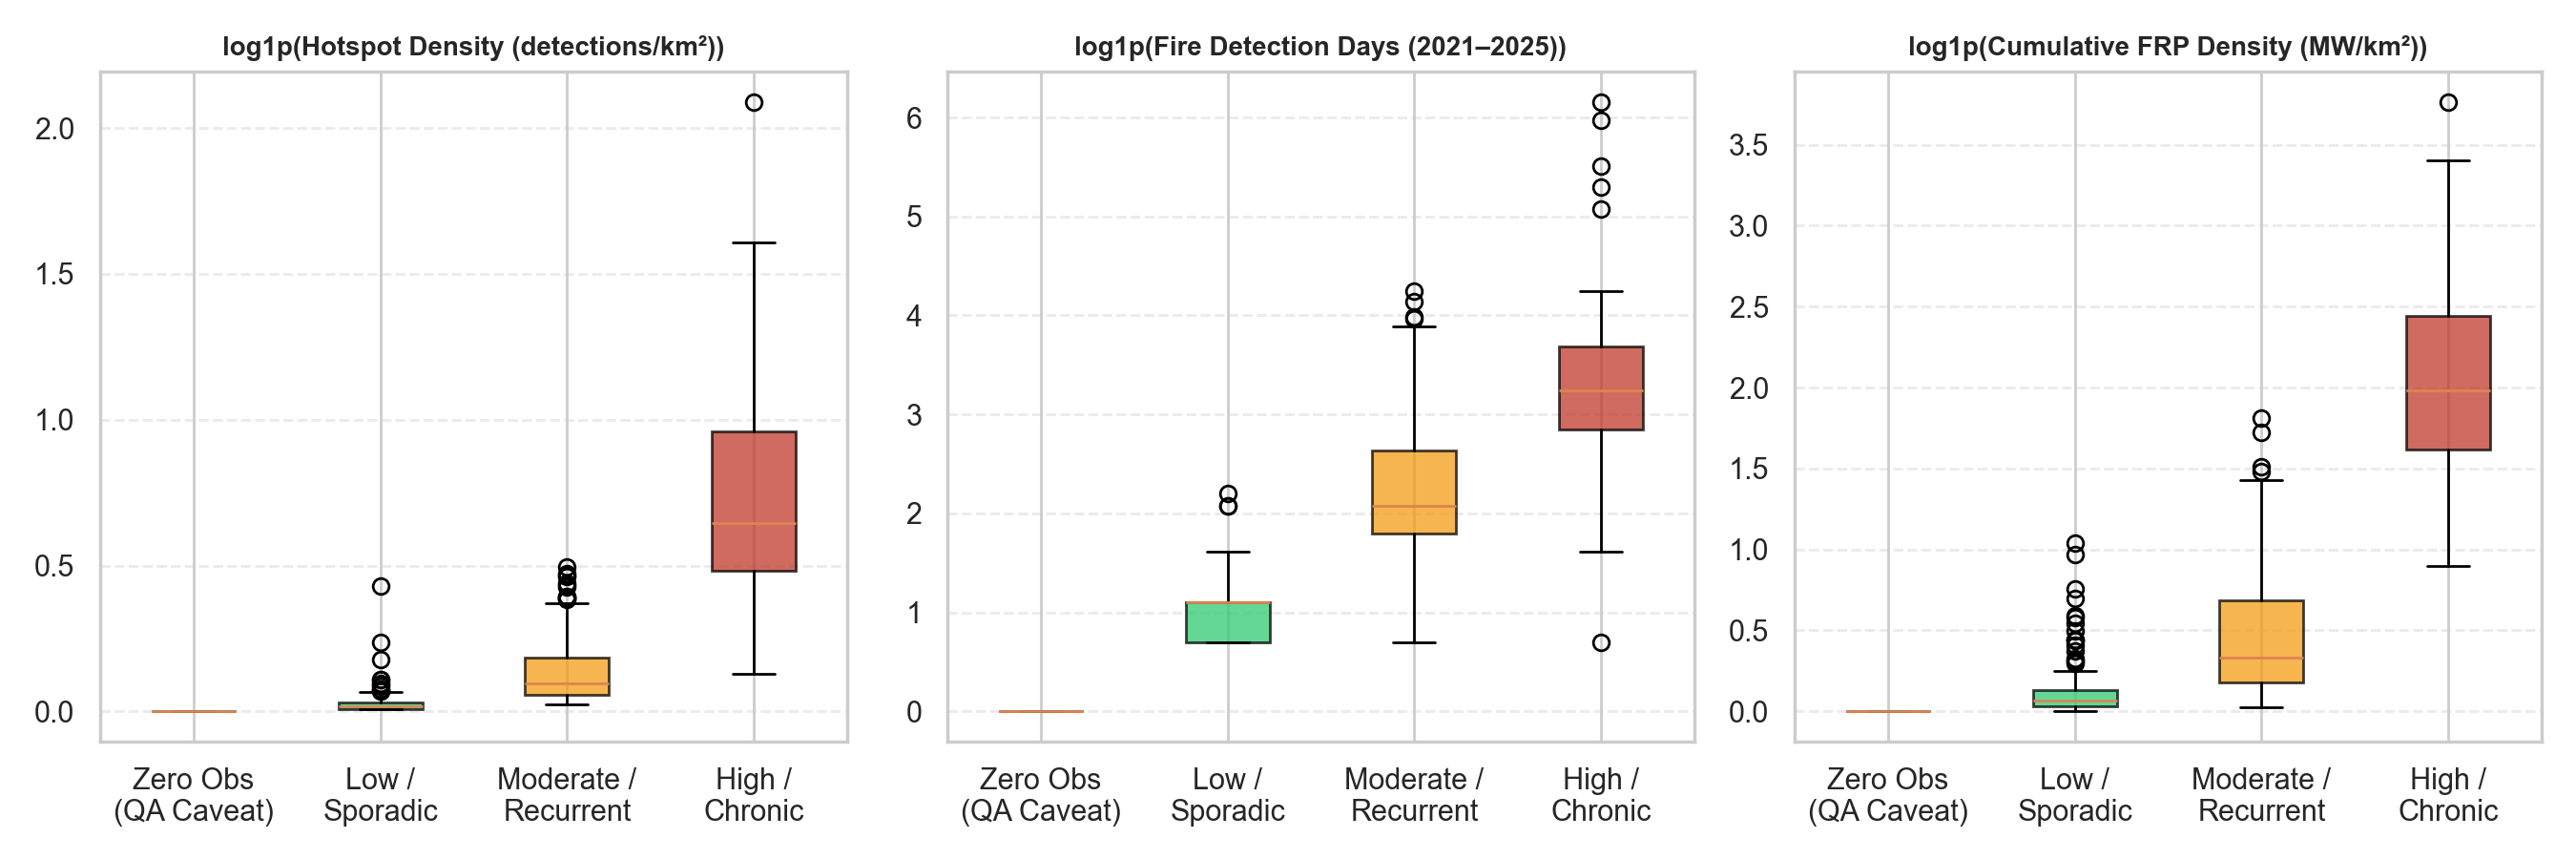

In [5]:
processed_dir = resolve_path(proj_cfg['paths']['processed_dir'], repo_root=REPO_ROOT)
profiles_df = pd.read_csv(reports_dir / 'vulnerability' / 'cluster_profiles.csv')
vuln_summary = json.loads((reports_dir / 'vulnerability' / 'vulnerability_summary.json').read_text(encoding='utf-8'))
df_vuln = pd.read_parquet(processed_dir / 'riau_vulnerability_profile.parquet')

display(profiles_df[profiles_df['model'] == 'K-Means (k=3)'])
print('K-Means vs DEC Tier Concordance:', vuln_summary['kmeans_dec_tier_agreement_pct'], '%')
print('Vulnerability Class Distribution:', df_vuln['vulnerability_class'].value_counts().to_dict())
display(pd.DataFrame(vuln_summary['weight_sensitivity']))
display(Image(filename=str(reports_dir / 'vulnerability' / 'vulnerability_class_profiles.png')))

## 5. Kesimpulan & Pencapaian Goals Bab 3.3 (Bab 8)
- **Model Terbaik Operasional:** `K-Means (k=3)` dengan cakupan 100% (`853` sel), DBI terendah (`0.7144`), stabilitas seed sempurna (`ARI=1.0000`), transfer spasial tertinggi (`ARI=0.9725`), generalization gap minimal (`-0.0062`), serta waktu latih `0.3147 s` & inferensi `0.00254 s`.
- **Peran Pelengkap Model 2 & 3:** `HDBSCAN` (`0.0121 s` fit) efektif mengisolasi `249` sel nol-deteksi dan `191` sel ekor kepadatan ekstrem (`79.06%` hotspot); `DEC` (`11.0475 s` training GPU, `0.00422 s` inferensi) menghasilkan ruang laten padat (`Latent Sil=0.8777`) dan menjadi pembanding konvergen (`87.34%` concordant).
- **Ketercapaian Goals & SDG 13.1:** Seluruh 5 goals (`G1–G5`) tercapai secara reproduksibel dalam batas data publik (`SRC-01/02/04/07 AVAILABLE`), dengan keterbatasan eksplisit pada sumber eksternal yang belum tersedia (`SRC-03/05/06/08/09 UNAVAILABLE`) dan inventori sintetis Fase 8 (`is_synthetic_scenario=True`).